In [1]:
!pip install -q "torchmetrics[image]"

In [2]:
import os, time, copy, math, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader, random_split
from torchvision import datasets
from torchvision.utils import make_grid

SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
os.makedirs("outputs", exist_ok=True)   # tempat simpan figur & bobot model
print("device:", device)

device: cuda


In [3]:
BATCH_SIZE = 128
HIDDEN     = 256    # ukuran hidden layer AE / VAE / MLP
LATENT     = 64     # dimensi laten AE, SAE, VAE, dan fitur MLP
NZ         = 100    # dimensi noise z untuk GAN & DCGAN
LAMBDA_L1  = 1e-2   # kekuatan penalti sparsity Sparse AE
T          = 1000   # jumlah langkah difusi DDPM

EPOCHS_AE, EPOCHS_GAN, EPOCHS_DCGAN, EPOCHS_DDPM, EPOCHS_MLP = 30, 50, 25, 30, 30

QUICK_TEST = False
if QUICK_TEST:
    EPOCHS_AE = EPOCHS_GAN = EPOCHS_DCGAN = EPOCHS_DDPM = EPOCHS_MLP = 1
    T = 50

In [4]:
train_raw = datasets.FashionMNIST("data", train=True, download=True)
test_raw  = datasets.FashionMNIST("data", train=False, download=True)

X = torch.cat([train_raw.data, test_raw.data]).float().div(255).unsqueeze(1)   # (70000, 1, 28, 28), nilai 0..1
Y = torch.cat([train_raw.targets, test_raw.targets])
CLASSES = ["T-shirt", "Trouser", "Pullover", "Dress", "Coat",
           "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

full = TensorDataset(X, Y)
n_train, n_val = int(0.8 * len(full)), int(0.1 * len(full))
n_test = len(full) - n_train - n_val
train_set, val_set, test_set = random_split(full, [n_train, n_val, n_test],
                                            generator=torch.Generator().manual_seed(SEED))

train_loader = DataLoader(train_set, BATCH_SIZE, shuffle=True, drop_last=True,
                          generator=torch.Generator().manual_seed(SEED))
val_loader   = DataLoader(val_set, BATCH_SIZE)
test_loader  = DataLoader(test_set, BATCH_SIZE)

x_test, y_test = X[test_set.indices], Y[test_set.indices]    # seluruh test set sebagai tensor (untuk metrik)
print("train / val / test:", len(train_set), len(val_set), len(test_set))

100%|██████████| 26.4M/26.4M [00:02<00:00, 10.8MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 177kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.05MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 20.3MB/s]


train / val / test: 56000 7000 7000


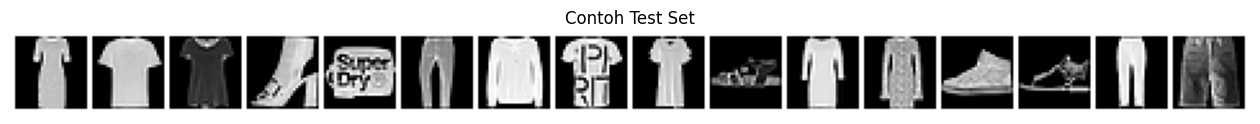

In [5]:
def to_minus1_1(x):          # [0,1] -> [-1,1]
    return x * 2 - 1

def to_0_1(x):               # [-1,1] -> [0,1]
    return ((x + 1) / 2).clamp(0, 1)

def show_grid(imgs, nrow=8, title=None, ax=None):
    grid = make_grid(imgs.cpu(), nrow=nrow, pad_value=1)
    ax = ax or plt.figure(figsize=(nrow, len(imgs) / nrow + 0.5)).gca()
    ax.imshow(grid.permute(1, 2, 0)); ax.axis("off")
    if title: ax.set_title(title)

show_grid(x_test[:16], nrow=16, title="Contoh Test Set"); plt.show()

In [6]:
class AE(nn.Module):
    def __init__(self, sparse=False):
        super().__init__()
        layers = [nn.Flatten(), nn.Linear(784, HIDDEN), nn.ReLU(), nn.Linear(HIDDEN, LATENT)]
        if sparse:
            layers.append(nn.ReLU())
        self.encoder = nn.Sequential(*layers)
        self.decoder = nn.Sequential(nn.Linear(LATENT, HIDDEN), nn.ReLU(),
                                     nn.Linear(HIDDEN, 784), nn.Sigmoid())

    def encode(self, x):
        return self.encoder(x)

    def decode(self, z):
        return self.decoder(z).view(-1, 1, 28, 28)

    def forward(self, x):
        z = self.encode(x)
        return self.decode(z), z

In [7]:
class VAE(nn.Module):
    def __init__(self):
        super().__init__()
        self.body = nn.Sequential(nn.Flatten(), nn.Linear(784, HIDDEN), nn.ReLU())
        self.fc_mu = nn.Linear(HIDDEN, LATENT)
        self.fc_logvar = nn.Linear(HIDDEN, LATENT)
        self.decoder = nn.Sequential(nn.Linear(LATENT, HIDDEN), nn.ReLU(),
                                     nn.Linear(HIDDEN, 784), nn.Sigmoid())

    def encode(self, x):                 # dipakai untuk rekonstruksi/interpolasi
        return self.fc_mu(self.body(x))

    def decode(self, z):
        return self.decoder(z).view(-1, 1, 28, 28)

    def forward(self, x):
        h = self.body(x)
        mu, logvar = self.fc_mu(h), self.fc_logvar(h)
        z = mu + torch.exp(0.5 * logvar) * torch.randn_like(mu)   # reparameterization trick
        return self.decode(z), mu, logvar

In [8]:
def recon_loss(x_hat, x):
    return F.mse_loss(x_hat, x, reduction="sum") / x.size(0)    # jumlah error kuadrat per gambar

def ae_loss(model, x, kind):
    if kind == "vae":
        x_hat, mu, logvar = model(x)
        kl = (-0.5 * torch.sum(1 + logvar - mu**2 - logvar.exp(), dim=1)).mean()
        rec = recon_loss(x_hat, x)
        return rec + kl, rec.item(), kl.item()

    x_hat, z = model(x)
    rec = recon_loss(x_hat, x)
    if kind == "sae":
        l1 = z.abs().sum(dim=1).mean()
        return rec + LAMBDA_L1 * l1, rec.item(), l1.item()
    return rec, rec.item(), 0.0

In [9]:
def train_autoencoder(model, kind, epochs=EPOCHS_AE):
    set_seed()
    model = model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    hist = {"train": [], "val": [], "recon": [], "reg": [], "time": []}
    best_val, best_state = float("inf"), None

    for ep in range(epochs):
        model.train()
        t0 = time.time()
        losses, recs, regs = [], [], []
        for x, _ in train_loader:
            x = x.to(device)
            loss, rec, reg = ae_loss(model, x, kind)
            opt.zero_grad(); loss.backward(); opt.step()
            losses.append(loss.item()); recs.append(rec); regs.append(reg)
        hist["time"].append(time.time() - t0)

        model.eval()
        with torch.no_grad():
            val = np.mean([ae_loss(model, x.to(device), kind)[0].item() for x, _ in val_loader])
        hist["train"].append(np.mean(losses)); hist["val"].append(val)
        hist["recon"].append(np.mean(recs));   hist["reg"].append(np.mean(regs))
        print(f"[{kind}] epoch {ep+1}/{epochs}  train {hist['train'][-1]:.2f}  val {val:.2f}")

        if val < best_val:
            best_val, best_state = val, copy.deepcopy(model.state_dict())

    model.load_state_dict(best_state)
    torch.save(best_state, f"outputs/{kind}.pt")
    return model.eval(), hist

In [10]:
ae,  hist_ae  = train_autoencoder(AE(sparse=False), "ae")
sae, hist_sae = train_autoencoder(AE(sparse=True),  "sae")
vae, hist_vae = train_autoencoder(VAE(),            "vae")

with torch.no_grad():
    active = (sae.encode(x_test[:2000].to(device)) > 0).float().mean().item()
print(f"Unit kode Sparse AE yang aktif: {active*100:.1f}%")

[ae] epoch 1/30  train 24.84  val 14.53
[ae] epoch 2/30  train 12.81  val 12.67
[ae] epoch 3/30  train 10.73  val 10.55
[ae] epoch 4/30  train 9.60  val 9.31
[ae] epoch 5/30  train 8.80  val 8.58
[ae] epoch 6/30  train 8.18  val 8.31
[ae] epoch 7/30  train 7.69  val 7.63
[ae] epoch 8/30  train 7.30  val 7.27
[ae] epoch 9/30  train 7.00  val 7.03
[ae] epoch 10/30  train 6.73  val 6.81
[ae] epoch 11/30  train 6.51  val 6.62
[ae] epoch 12/30  train 6.32  val 6.42
[ae] epoch 13/30  train 6.14  val 6.26
[ae] epoch 14/30  train 5.98  val 6.11
[ae] epoch 15/30  train 5.86  val 6.01
[ae] epoch 16/30  train 5.74  val 5.86
[ae] epoch 17/30  train 5.62  val 5.77
[ae] epoch 18/30  train 5.53  val 5.71
[ae] epoch 19/30  train 5.43  val 5.62
[ae] epoch 20/30  train 5.36  val 5.53
[ae] epoch 21/30  train 5.28  val 5.45
[ae] epoch 22/30  train 5.21  val 5.45
[ae] epoch 23/30  train 5.17  val 5.40
[ae] epoch 24/30  train 5.11  val 5.32
[ae] epoch 25/30  train 5.08  val 5.30
[ae] epoch 26/30  train 5.03

In [11]:
class MLPGenerator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(NZ, 256),   nn.LeakyReLU(0.2),
            nn.Linear(256, 512),  nn.LeakyReLU(0.2),
            nn.Linear(512, 1024), nn.LeakyReLU(0.2),
            nn.Linear(1024, 784), nn.Tanh())

    def forward(self, z):
        return self.net(z).view(-1, 1, 28, 28)


class MLPDiscriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 512), nn.LeakyReLU(0.2),
            nn.Linear(512, 256), nn.LeakyReLU(0.2),
            nn.Linear(256, 1))

    def forward(self, x):
        return self.net(x).view(-1)

In [12]:
class DCGenerator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.ConvTranspose2d(NZ, 256, 7, 1, 0, bias=False), nn.BatchNorm2d(256), nn.ReLU(),  # 7x7
            nn.ConvTranspose2d(256, 128, 4, 2, 1, bias=False), nn.BatchNorm2d(128), nn.ReLU(), # 14x14
            nn.ConvTranspose2d(128, 1, 4, 2, 1, bias=False), nn.Tanh())                        # 28x28

    def forward(self, z):
        return self.net(z.view(-1, NZ, 1, 1))


class DCDiscriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 64, 4, 2, 1, bias=False), nn.LeakyReLU(0.2),                          # 14x14
            nn.Conv2d(64, 128, 4, 2, 1, bias=False), nn.BatchNorm2d(128), nn.LeakyReLU(0.2),   # 7x7
            nn.Conv2d(128, 1, 7, 1, 0, bias=False))                                            # 1x1

    def forward(self, x):
        return self.net(x).view(-1)


def dcgan_init(m):
    if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.normal_(m.weight, 0.0, 0.02)
    elif isinstance(m, nn.BatchNorm2d):
        nn.init.normal_(m.weight, 1.0, 0.02); nn.init.zeros_(m.bias)

In [13]:
def train_gan(G, D, name, epochs):
    set_seed()
    G, D = G.to(device), D.to(device)
    optG = torch.optim.Adam(G.parameters(), lr=2e-4, betas=(0.5, 0.999))
    optD = torch.optim.Adam(D.parameters(), lr=2e-4, betas=(0.5, 0.999))
    bce = nn.BCEWithLogitsLoss()
    hist = {"G": [], "D": [], "time": []}

    for ep in range(epochs):
        G.train(); D.train()
        t0 = time.time()
        d_real_avg, d_fake_avg = [], []
        for x, _ in train_loader:
            x = to_minus1_1(x.to(device))
            b = x.size(0)
            real_label, fake_label = torch.ones(b, device=device), torch.zeros(b, device=device)

            # Langkah 1: update Discriminator
            fake = G(torch.randn(b, NZ, device=device))
            out_real, out_fake = D(x), D(fake.detach())
            loss_D = bce(out_real, real_label) + bce(out_fake, fake_label)
            optD.zero_grad(); loss_D.backward(); optD.step()

            # Langkah 2: update Generator (non-saturating)
            loss_G = bce(D(fake), real_label)
            optG.zero_grad(); loss_G.backward(); optG.step()

            hist["G"].append(loss_G.item()); hist["D"].append(loss_D.item())
            d_real_avg.append(torch.sigmoid(out_real).mean().item())
            d_fake_avg.append(torch.sigmoid(out_fake).mean().item())
        hist["time"].append(time.time() - t0)
        print(f"[{name}] epoch {ep+1}/{epochs}  G {np.mean(hist['G'][-len(train_loader):]):.3f}  "
              f"D {np.mean(hist['D'][-len(train_loader):]):.3f}  D(x) {np.mean(d_real_avg):.2f}  D(G(z)) {np.mean(d_fake_avg):.2f}")

    torch.save(G.state_dict(), f"outputs/{name}.pt")
    return G.eval(), hist

[gan] epoch 1/50  G 1.254  D 0.906  D(x) 0.81  D(G(z)) 0.45
[gan] epoch 2/50  G 1.827  D 0.931  D(x) 0.70  D(G(z)) 0.36
[gan] epoch 3/50  G 1.964  D 0.946  D(x) 0.69  D(G(z)) 0.34
[gan] epoch 4/50  G 1.649  D 0.996  D(x) 0.67  D(G(z)) 0.35
[gan] epoch 5/50  G 1.536  D 1.062  D(x) 0.64  D(G(z)) 0.37
[gan] epoch 6/50  G 1.334  D 1.110  D(x) 0.62  D(G(z)) 0.39
[gan] epoch 7/50  G 1.293  D 1.131  D(x) 0.61  D(G(z)) 0.40
[gan] epoch 8/50  G 1.229  D 1.168  D(x) 0.60  D(G(z)) 0.41
[gan] epoch 9/50  G 1.194  D 1.198  D(x) 0.58  D(G(z)) 0.42
[gan] epoch 10/50  G 1.168  D 1.197  D(x) 0.58  D(G(z)) 0.42
[gan] epoch 11/50  G 1.089  D 1.227  D(x) 0.57  D(G(z)) 0.43
[gan] epoch 12/50  G 1.118  D 1.230  D(x) 0.57  D(G(z)) 0.43
[gan] epoch 13/50  G 1.103  D 1.234  D(x) 0.57  D(G(z)) 0.43
[gan] epoch 14/50  G 1.061  D 1.238  D(x) 0.57  D(G(z)) 0.44
[gan] epoch 15/50  G 1.034  D 1.265  D(x) 0.56  D(G(z)) 0.44
[gan] epoch 16/50  G 0.995  D 1.271  D(x) 0.55  D(G(z)) 0.45
[gan] epoch 17/50  G 0.985  D 1.2

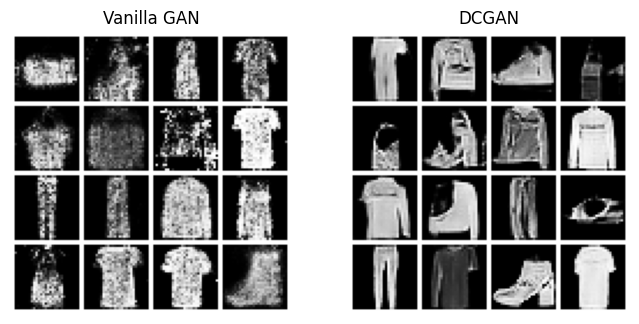

In [14]:
gan_G, hist_gan = train_gan(MLPGenerator(), MLPDiscriminator(), "gan", EPOCHS_GAN)

dcG, dcD = DCGenerator(), DCDiscriminator()
dcG.apply(dcgan_init); dcD.apply(dcgan_init)
dcgan_G, hist_dcgan = train_gan(dcG, dcD, "dcgan", EPOCHS_DCGAN)

with torch.no_grad():
    z = torch.randn(16, NZ, device=device)
    fig, axes = plt.subplots(1, 2, figsize=(8, 4))
    show_grid(to_0_1(gan_G(z)), nrow=4, title="Vanilla GAN", ax=axes[0])
    show_grid(to_0_1(dcgan_G(z)), nrow=4, title="DCGAN", ax=axes[1])
    plt.show()

In [15]:
def time_embedding(t, dim):
    half = dim // 2
    freqs = torch.exp(-math.log(10000) * torch.arange(half, device=t.device) / half)
    args = t.float()[:, None] * freqs[None]
    return torch.cat([torch.sin(args), torch.cos(args)], dim=1)


class ResBlock(nn.Module):
    def __init__(self, c_in, c_out, t_dim):
        super().__init__()
        self.block1 = nn.Sequential(nn.GroupNorm(8, c_in), nn.SiLU(), nn.Conv2d(c_in, c_out, 3, padding=1))
        self.t_proj = nn.Linear(t_dim, c_out)
        self.block2 = nn.Sequential(nn.GroupNorm(8, c_out), nn.SiLU(), nn.Conv2d(c_out, c_out, 3, padding=1))
        self.skip = nn.Conv2d(c_in, c_out, 1) if c_in != c_out else nn.Identity()

    def forward(self, x, t_emb):
        h = self.block1(x) + self.t_proj(t_emb)[:, :, None, None]   # tambahkan info waktu
        return self.block2(h) + self.skip(x)


class UNet(nn.Module):
    def __init__(self, ch=64, t_dim=256):
        super().__init__()
        self.ch = ch
        self.t_mlp = nn.Sequential(nn.Linear(ch, t_dim), nn.SiLU(), nn.Linear(t_dim, t_dim))
        self.inc   = nn.Conv2d(1, ch, 3, padding=1)
        self.down1 = ResBlock(ch, ch, t_dim)                      # 28x28
        self.pool1 = nn.Conv2d(ch, ch, 3, stride=2, padding=1)    # -> 14x14
        self.down2 = ResBlock(ch, 2 * ch, t_dim)
        self.pool2 = nn.Conv2d(2 * ch, 2 * ch, 3, stride=2, padding=1)  # -> 7x7
        self.mid   = ResBlock(2 * ch, 2 * ch, t_dim)
        self.up2   = nn.Upsample(scale_factor=2)                  # -> 14x14
        self.dec2  = ResBlock(4 * ch, 2 * ch, t_dim)
        self.up1   = nn.Upsample(scale_factor=2)                  # -> 28x28
        self.dec1  = ResBlock(3 * ch, ch, t_dim)
        self.out   = nn.Sequential(nn.GroupNorm(8, ch), nn.SiLU(), nn.Conv2d(ch, 1, 3, padding=1))

    def forward(self, x, t):
        te = self.t_mlp(time_embedding(t, self.ch))
        h1 = self.down1(self.inc(x), te)
        h2 = self.down2(self.pool1(h1), te)
        h  = self.mid(self.pool2(h2), te)
        h  = self.dec2(torch.cat([self.up2(h), h2], dim=1), te)   # skip connection
        h  = self.dec1(torch.cat([self.up1(h), h1], dim=1), te)   # skip connection
        return self.out(h)

In [16]:
betas = torch.linspace(1e-4, 0.02, T, device=device)
alphas = 1 - betas
alpha_bar = torch.cumprod(alphas, dim=0)

def add_noise(x0, t, noise):
    a = alpha_bar[t].view(-1, 1, 1, 1)
    return a.sqrt() * x0 + (1 - a).sqrt() * noise

def ddpm_loss(model, x0):
    t = torch.randint(0, T, (x0.size(0),), device=device)
    noise = torch.randn_like(x0)
    return F.mse_loss(model(add_noise(x0, t, noise), t), noise)

@torch.no_grad()
def ddpm_sample(model, n, keep=()):
    x = torch.randn(n, 1, 28, 28, device=device)          # x_T = noise murni
    saved = {T: x.clone()} if T in keep else {}
    for t in reversed(range(T)):
        tt = torch.full((n,), t, device=device, dtype=torch.long)
        eps = model(x, tt)
        x = (x - betas[t] / (1 - alpha_bar[t]).sqrt() * eps) / alphas[t].sqrt()
        if t > 0:
            x = x + betas[t].sqrt() * torch.randn_like(x)
        if t in keep:
            saved[t] = x.clone()
    x = x.clamp(-1, 1)
    return (x, saved) if keep else x

[ddpm] epoch 1/30  loss 0.0859  (42s)
[ddpm] epoch 2/30  loss 0.0517  (41s)
[ddpm] epoch 3/30  loss 0.0467  (41s)
[ddpm] epoch 4/30  loss 0.0446  (41s)
[ddpm] epoch 5/30  loss 0.0438  (41s)
[ddpm] epoch 6/30  loss 0.0428  (41s)
[ddpm] epoch 7/30  loss 0.0414  (41s)
[ddpm] epoch 8/30  loss 0.0415  (41s)
[ddpm] epoch 9/30  loss 0.0407  (41s)
[ddpm] epoch 10/30  loss 0.0413  (42s)
[ddpm] epoch 11/30  loss 0.0399  (41s)
[ddpm] epoch 12/30  loss 0.0399  (41s)
[ddpm] epoch 13/30  loss 0.0395  (41s)
[ddpm] epoch 14/30  loss 0.0391  (41s)
[ddpm] epoch 15/30  loss 0.0391  (41s)
[ddpm] epoch 16/30  loss 0.0387  (41s)
[ddpm] epoch 17/30  loss 0.0385  (42s)
[ddpm] epoch 18/30  loss 0.0387  (41s)
[ddpm] epoch 19/30  loss 0.0382  (41s)
[ddpm] epoch 20/30  loss 0.0383  (42s)
[ddpm] epoch 21/30  loss 0.0380  (42s)
[ddpm] epoch 22/30  loss 0.0386  (41s)
[ddpm] epoch 23/30  loss 0.0379  (41s)
[ddpm] epoch 24/30  loss 0.0379  (41s)
[ddpm] epoch 25/30  loss 0.0376  (41s)
[ddpm] epoch 26/30  loss 0.0374  (

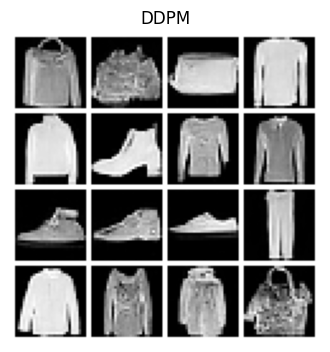

In [17]:
def train_ddpm(epochs=EPOCHS_DDPM):
    set_seed()
    model = UNet().to(device)
    ema = copy.deepcopy(model).eval()
    opt = torch.optim.Adam(model.parameters(), lr=2e-4)
    hist = {"loss": [], "time": []}

    for ep in range(epochs):
        model.train()
        t0 = time.time()
        for x, _ in train_loader:
            loss = ddpm_loss(model, to_minus1_1(x.to(device)))
            opt.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            with torch.no_grad():                                   # update EMA
                for p_ema, p in zip(ema.parameters(), model.parameters()):
                    p_ema.mul_(0.999).add_(p, alpha=0.001)
            hist["loss"].append(loss.item())
        hist["time"].append(time.time() - t0)
        print(f"[ddpm] epoch {ep+1}/{epochs}  loss {np.mean(hist['loss'][-len(train_loader):]):.4f}  ({hist['time'][-1]:.0f}s)")

    torch.save(ema.state_dict(), "outputs/ddpm.pt")
    return ema, hist

ddpm, hist_ddpm = train_ddpm()
show_grid(to_0_1(ddpm_sample(ddpm, 16)), nrow=4, title="DDPM"); plt.show()

In [18]:
class MLPClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(784, HIDDEN)     # W1: 256 x 784
        self.fc2 = nn.Linear(HIDDEN, LATENT)  # W2: 64 x 256
        self.fc3 = nn.Linear(LATENT, 10)      # W3: 10 x 64

    def features(self, x):                    # z_MLP (64 dimensi)
        return F.relu(self.fc2(F.relu(self.fc1(x.flatten(1)))))

    def forward(self, x):
        return self.fc3(self.features(x))


def accuracy(model, loader):
    correct = total = 0
    with torch.no_grad():
        for x, y in loader:
            correct += (model(x.to(device)).argmax(1).cpu() == y).sum().item()
            total += len(y)
    return correct / total

set_seed()
mlp = MLPClassifier().to(device)
opt = torch.optim.Adam(mlp.parameters(), lr=1e-3)
best_acc, best_state = 0, None
for ep in range(EPOCHS_MLP):
    mlp.train()
    for x, y in train_loader:
        loss = F.cross_entropy(mlp(x.to(device)), y.to(device))
        opt.zero_grad(); loss.backward(); opt.step()
    mlp.eval()
    val_acc = accuracy(mlp, val_loader)
    if val_acc > best_acc:
        best_acc, best_state = val_acc, copy.deepcopy(mlp.state_dict())
    print(f"[mlp] epoch {ep+1}/{EPOCHS_MLP}  val acc {val_acc:.4f}")

mlp.load_state_dict(best_state); mlp.eval()
test_acc = accuracy(mlp, test_loader)
print(f"TEST ACCURACY MLP = {test_acc:.4f}")

[mlp] epoch 1/30  val acc 0.8331
[mlp] epoch 2/30  val acc 0.8580
[mlp] epoch 3/30  val acc 0.8634
[mlp] epoch 4/30  val acc 0.8701
[mlp] epoch 5/30  val acc 0.8759
[mlp] epoch 6/30  val acc 0.8756
[mlp] epoch 7/30  val acc 0.8814
[mlp] epoch 8/30  val acc 0.8796
[mlp] epoch 9/30  val acc 0.8831
[mlp] epoch 10/30  val acc 0.8843
[mlp] epoch 11/30  val acc 0.8899
[mlp] epoch 12/30  val acc 0.8921
[mlp] epoch 13/30  val acc 0.8919
[mlp] epoch 14/30  val acc 0.8894
[mlp] epoch 15/30  val acc 0.8853
[mlp] epoch 16/30  val acc 0.8886
[mlp] epoch 17/30  val acc 0.8920
[mlp] epoch 18/30  val acc 0.8954
[mlp] epoch 19/30  val acc 0.8907
[mlp] epoch 20/30  val acc 0.8989
[mlp] epoch 21/30  val acc 0.8946
[mlp] epoch 22/30  val acc 0.8930
[mlp] epoch 23/30  val acc 0.8960
[mlp] epoch 24/30  val acc 0.8960
[mlp] epoch 25/30  val acc 0.8931
[mlp] epoch 26/30  val acc 0.8911
[mlp] epoch 27/30  val acc 0.8973
[mlp] epoch 28/30  val acc 0.8959
[mlp] epoch 29/30  val acc 0.8917
[mlp] epoch 30/30  val 

In [19]:
rows = []
for name, layer in [("W1", mlp.fc1), ("W2", mlp.fc2), ("W3", mlp.fc3)]:
    W = layer.weight.detach().cpu().double()
    I = torch.eye(W.shape[1], dtype=torch.float64)
    rows.append({"bobot": name, "ukuran": tuple(W.shape), "rank": int(torch.linalg.matrix_rank(W)),
                 "error ||W^T W - I|| / ||I||": round(float(torch.linalg.norm(W.T @ W - I) / torch.linalg.norm(I)), 3)})
display(pd.DataFrame(rows))

with torch.no_grad():
    z_test = mlp.features(x_test.to(device))
print(f"Fraksi aktivasi z_MLP yang nol (dibuang ReLU): {(z_test == 0).float().mean().item():.3f}")

,bobot,ukuran,rank,error ||W^T W - I|| / ||I||
0,W1,"(256, 784)",256,15.973
1,W2,"(64, 256)",64,3.756
2,W3,"(10, 64)",10,1.539


Fraksi aktivasi z_MLP yang nol (dibuang ReLU): 0.512


In [20]:
W1, W2, W3 = mlp.fc1.weight.detach(), mlp.fc2.weight.detach(), mlp.fc3.weight.detach()

with torch.no_grad():
    # Tahap 2: dari one-hot kelas
    y_onehot = torch.eye(10, device=device)
    x_from_class = torch.sigmoid(F.relu(F.relu(y_onehot @ W3) @ W2) @ W1).view(-1, 1, 28, 28).cpu()

    # Tahap 3: dari fitur laten gambar test
    x_from_latent = torch.sigmoid(F.relu(z_test @ W2) @ W1).view(-1, 1, 28, 28).cpu()

    # Kontrol: pseudo-inverse (bias dikurangi dulu)
    h_pinv = (z_test - mlp.fc2.bias) @ torch.linalg.pinv(W2).T
    x_pinv = ((h_pinv - mlp.fc1.bias) @ torch.linalg.pinv(W1).T).clamp(0, 1).view(-1, 1, 28, 28).cpu()

def minmax(imgs):      # hanya untuk tampilan: regangkan kontras supaya polanya kelihatan
    f = imgs.flatten(1)
    f = (f - f.min(1, keepdim=True).values) / (f.max(1, keepdim=True).values - f.min(1, keepdim=True).values + 1e-8)
    return f.view_as(imgs)

In [21]:
set_seed()
for p in mlp.parameters():
    p.requires_grad = False                       # MLP dibekukan

mlp_decoder = nn.Sequential(nn.Linear(LATENT, HIDDEN), nn.ReLU(),
                            nn.Linear(HIDDEN, 784), nn.Sigmoid()).to(device)   # arsitektur sama dengan decoder AE
opt = torch.optim.Adam(mlp_decoder.parameters(), lr=1e-3)
for ep in range(EPOCHS_AE):
    for x, _ in train_loader:
        x = x.to(device)
        x_hat = mlp_decoder(mlp.features(x)).view(-1, 1, 28, 28)
        loss = recon_loss(x_hat, x)              # loss yang sama dengan AE
        opt.zero_grad(); loss.backward(); opt.step()
    print(f"[frozen decoder] epoch {ep+1}/{EPOCHS_AE}  loss {loss.item():.2f}")
mlp_decoder.eval()

with torch.no_grad():
    x_frozen = mlp_decoder(z_test).view(-1, 1, 28, 28).cpu()
    x_ae = ae.decode(ae.encode(x_test.to(device))).cpu()

x_train, y_train = X[train_set.indices], Y[train_set.indices]
class_means = torch.stack([x_train[y_train == c].mean(0) for c in range(10)])
x_class_mean = class_means[y_test]                # tebakan "rata-rata kelas" untuk tiap gambar test

[frozen decoder] epoch 1/30  loss 20.22
[frozen decoder] epoch 2/30  loss 17.81
[frozen decoder] epoch 3/30  loss 17.76
[frozen decoder] epoch 4/30  loss 17.43
[frozen decoder] epoch 5/30  loss 16.94
[frozen decoder] epoch 6/30  loss 14.93
[frozen decoder] epoch 7/30  loss 15.78
[frozen decoder] epoch 8/30  loss 13.23
[frozen decoder] epoch 9/30  loss 14.61
[frozen decoder] epoch 10/30  loss 14.05
[frozen decoder] epoch 11/30  loss 13.90
[frozen decoder] epoch 12/30  loss 13.88
[frozen decoder] epoch 13/30  loss 13.07
[frozen decoder] epoch 14/30  loss 13.67
[frozen decoder] epoch 15/30  loss 15.39
[frozen decoder] epoch 16/30  loss 14.86
[frozen decoder] epoch 17/30  loss 13.08
[frozen decoder] epoch 18/30  loss 15.83
[frozen decoder] epoch 19/30  loss 14.44
[frozen decoder] epoch 20/30  loss 14.13
[frozen decoder] epoch 21/30  loss 12.78
[frozen decoder] epoch 22/30  loss 13.67
[frozen decoder] epoch 23/30  loss 13.80
[frozen decoder] epoch 24/30  loss 13.87
[frozen decoder] epoch 25

In [22]:
set_seed()
with torch.no_grad():
    z_rand = z_test.mean(0) + z_test.std(0) * torch.randn_like(z_test)
    sample_mlp = mlp_decoder(z_rand).view(-1, 1, 28, 28).cpu()

    z_ae = ae.encode(x_test.to(device))
    z_rand_ae = z_ae.mean(0) + z_ae.std(0) * torch.randn_like(z_ae)
    sample_ae_latent = ae.decode(z_rand_ae).cpu()

print(f"Persentase nilai z_rand yang negatif (tidak pernah muncul di z_MLP asli): {(z_rand < 0).float().mean().item()*100:.1f}%")

Persentase nilai z_rand yang negatif (tidak pernah muncul di z_MLP asli): 18.9%


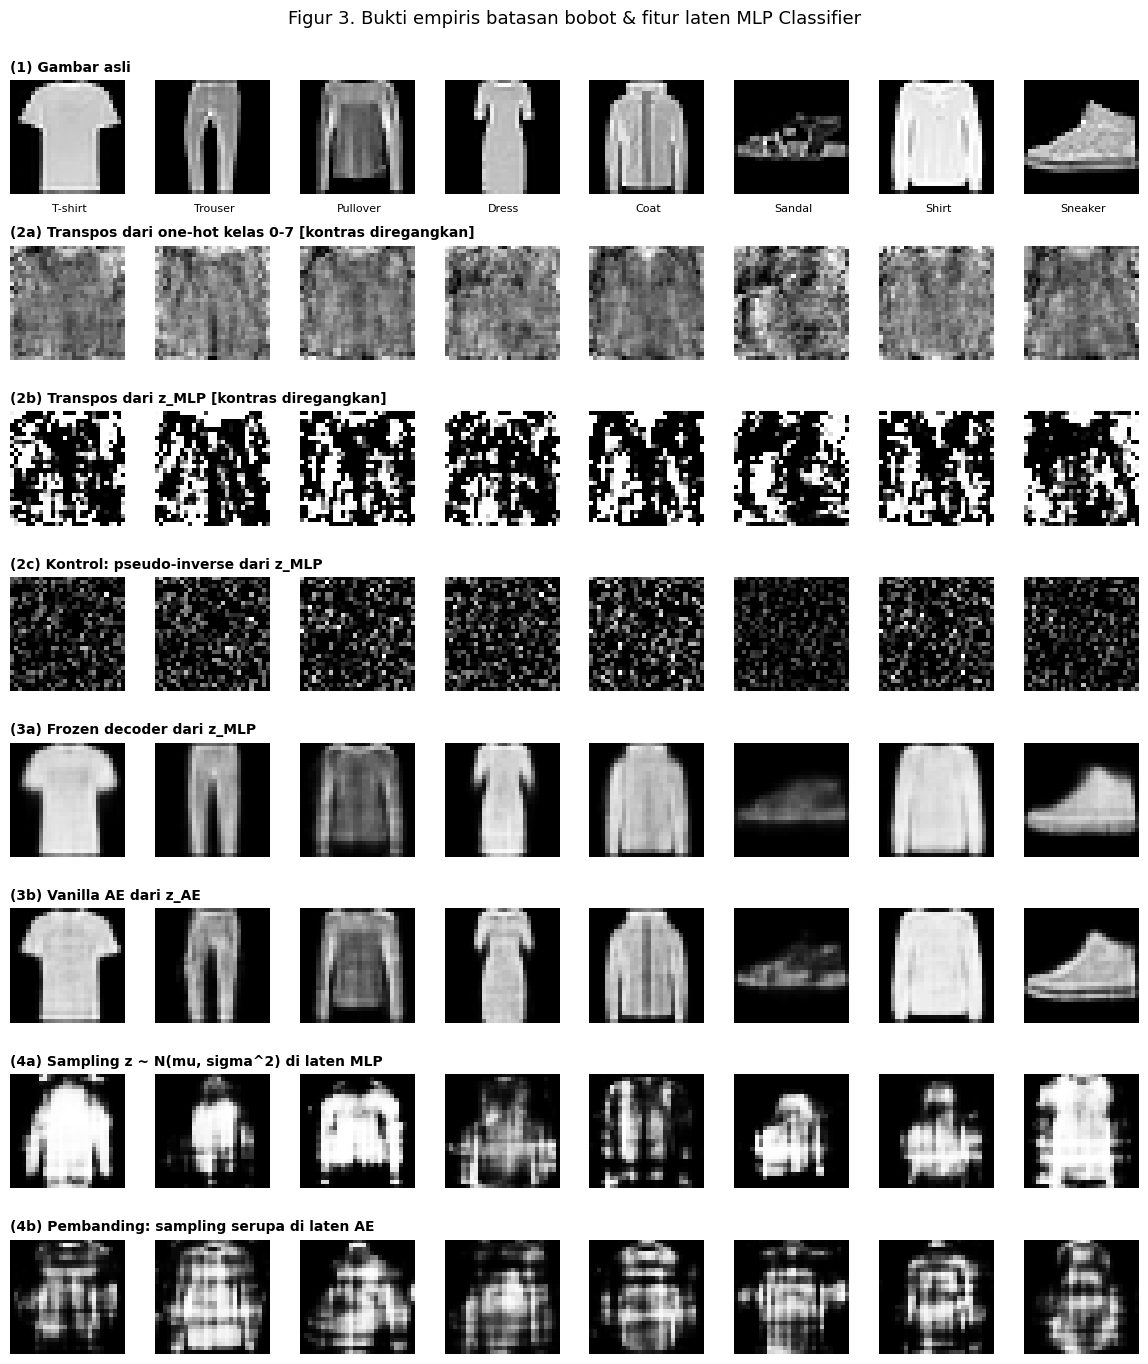

In [23]:
idx = torch.stack([torch.nonzero(y_test == c)[0, 0] for c in range(8)])    # 1 gambar per kelas 0..7
rows = [
    ("(1) Gambar asli", x_test[idx]),
    ("(2a) Transpos dari one-hot kelas 0-7 [kontras diregangkan]", minmax(x_from_class[:8])),
    ("(2b) Transpos dari z_MLP [kontras diregangkan]", minmax(x_from_latent[idx])),
    ("(2c) Kontrol: pseudo-inverse dari z_MLP", x_pinv[idx]),
    ("(3a) Frozen decoder dari z_MLP", x_frozen[idx]),
    ("(3b) Vanilla AE dari z_AE", x_ae[idx]),
    ("(4a) Sampling z ~ N(mu, sigma^2) di laten MLP", sample_mlp[:8]),
    ("(4b) Pembanding: sampling serupa di laten AE", sample_ae_latent[:8]),
]
fig, axes = plt.subplots(len(rows), 8, figsize=(12, 14))
fig.subplots_adjust(hspace=0.45, wspace=0.05, top=0.93, bottom=0.02, left=0.02, right=0.98)
for r, (title, imgs) in enumerate(rows):
    for c in range(8):
        axes[r, c].imshow(imgs[c, 0], cmap="gray", vmin=0, vmax=1); axes[r, c].axis("off")
    axes[r, 0].set_title(title, loc="left", fontsize=10, fontweight="bold")
for c in range(8):
    axes[0, c].text(14, 30, CLASSES[c], ha="center", va="top", fontsize=8)
fig.suptitle("Figur 3. Bukti empiris batasan bobot & fitur laten MLP Classifier", fontsize=13)
plt.savefig("outputs/fig3_mlp_limits.png", dpi=300, bbox_inches="tight"); plt.show()

In [24]:
from torchmetrics.functional.image import structural_similarity_index_measure as ssim_fn
from torchmetrics.image.fid import FrechetInceptionDistance

def recon_metrics(x_hat, x):
    mse_per_img = ((x_hat - x) ** 2).flatten(1).mean(1)
    psnr = 10 * torch.log10(1 / mse_per_img.clamp_min(1e-10))
    ssim = ssim_fn(x_hat, x, data_range=1.0)
    return {"MSE": mse_per_img.mean().item(), "PSNR (dB)": psnr.mean().item(), "SSIM": ssim.item()}

def compute_fid(real, fake):
    fid = FrechetInceptionDistance(feature=2048, normalize=True).to(device)
    for i in range(0, len(real), 250):
        fid.update(real[i:i+250].to(device).repeat(1, 3, 1, 1), real=True)
        fid.update(fake[i:i+250].to(device).repeat(1, 3, 1, 1), real=False)
    return fid.compute().item()

def latency_ms(fn, runs=20):
    fn()                                            # warm-up
    if device.type == "cuda": torch.cuda.synchronize()
    t0 = time.time()
    for _ in range(runs):
        fn()
    if device.type == "cuda": torch.cuda.synchronize()
    return (time.time() - t0) / runs * 1000

In [25]:
@torch.no_grad()
def generate(name, n):
    out = []
    for i in range(0, n, 500):
        b = min(500, n - i)
        if name == "VAE":
            imgs = vae.decode(torch.randn(b, LATENT, device=device))
        elif name == "Vanilla GAN":
            imgs = to_0_1(gan_G(torch.randn(b, NZ, device=device)))
        elif name == "DCGAN":
            imgs = to_0_1(dcgan_G(torch.randn(b, NZ, device=device)))
        else:
            imgs = to_0_1(ddpm_sample(ddpm, b))
        out.append(imgs.cpu())
    return torch.cat(out)

In [26]:
set_seed()
x64 = x_test[:64].to(device)
z64 = torch.randn(64, LATENT, device=device)
n64 = torch.randn(64, NZ, device=device)
table = []

for name, model, hist in [("Vanilla AE", ae, hist_ae), ("Sparse AE", sae, hist_sae), ("VAE", vae, hist_vae)]:
    with torch.no_grad():
        x_hat = torch.cat([model.decode(model.encode(x_test[i:i+1000].to(device))).cpu()
                           for i in range(0, len(x_test), 1000)])
    row = {"Model": name, "Dim Laten": LATENT, "Train/epoch (s)": np.mean(hist["time"])}
    row.update(recon_metrics(x_hat, x_test))
    with torch.no_grad():
        if name == "VAE":
            row["Latency (ms/64)"] = latency_ms(lambda: vae.decode(z64))
        else:
            row["Latency (ms/64)"] = latency_ms(lambda: model.decode(model.encode(x64)))
    table.append(row)

with torch.no_grad():
    for name, G, hist in [("Vanilla GAN", gan_G, hist_gan), ("DCGAN", dcgan_G, hist_dcgan)]:
        table.append({"Model": name, "Dim Laten": NZ, "Train/epoch (s)": np.mean(hist["time"]),
                      "Latency (ms/64)": latency_ms(lambda: G(n64))})
    table.append({"Model": "DDPM", "Dim Laten": "1x28x28", "Train/epoch (s)": np.mean(hist_ddpm["time"]),
                  "Latency (ms/64)": latency_ms(lambda: ddpm_sample(ddpm, 64), runs=2)})

for row in table:
    if row["Model"] in ("VAE", "Vanilla GAN", "DCGAN", "DDPM"):
        print("Menghitung FID", row["Model"], "...")
        row["FID"] = compute_fid(x_test, generate(row["Model"], len(x_test)))

df = pd.DataFrame(table).set_index("Model").round(4)
df.to_csv("outputs/metrics.csv")
display(df)

mlp_table = pd.DataFrame({
    "Tahap 3: transpos dari z_MLP":     recon_metrics(x_from_latent, x_test),
    "Tahap 3: kontrol pseudo-inverse":  recon_metrics(x_pinv, x_test),
    "Tahap 4: frozen decoder (z_MLP)":  recon_metrics(x_frozen, x_test),
    "Tahap 4: Vanilla AE (z_AE)":       recon_metrics(x_ae, x_test),
    "Baseline: rata-rata kelas":        recon_metrics(x_class_mean, x_test),
}).T.round(4)
mlp_table.loc["Tahap 5: FID sampel laten MLP", "FID"] = compute_fid(x_test, sample_mlp)
mlp_table.loc["Tahap 5: FID sampel laten AE", "FID"] = compute_fid(x_test, sample_ae_latent)
display(mlp_table)

Menghitung FID VAE ...


Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/weights-inception-2015-12-05-6726825d.pth
100%|██████████| 91.2M/91.2M [00:02<00:00, 40.4MB/s]


Menghitung FID Vanilla GAN ...
Menghitung FID DCGAN ...
Menghitung FID DDPM ...


,Dim Laten,Train/epoch (s),MSE,PSNR (dB),SSIM,Latency (ms/64),FID
Model,,,,,,,
Vanilla AE,64,1.4567,0.0065,23.0148,0.8663,0.1987,NaN
Sparse AE,64,1.5443,0.0082,21.9213,0.8341,0.2026,NaN
VAE,64,1.7852,0.0173,18.3098,0.6986,0.1027,87.3689
Vanilla GAN,100,2.9061,NaN,NaN,NaN,0.2413,126.9229
DCGAN,100,17.1768,NaN,NaN,NaN,11.2495,21.1571
DDPM,1x28x28,41.3727,NaN,NaN,NaN,16673.5591,11.4033


,MSE,PSNR (dB),SSIM,FID
Tahap 3: transpos dari z_MLP,0.3045,5.2129,0.0458,NaN
Tahap 3: kontrol pseudo-inverse,0.1924,7.7519,0.0129,NaN
Tahap 4: frozen decoder (z_MLP),0.0177,18.3151,0.7135,NaN
Tahap 4: Vanilla AE (z_AE),0.0065,23.0148,0.8663,NaN
Baseline: rata-rata kelas,0.0528,13.3877,0.4268,NaN
Tahap 5: FID sampel laten MLP,NaN,NaN,NaN,148.050735
Tahap 5: FID sampel laten AE,NaN,NaN,NaN,209.989777


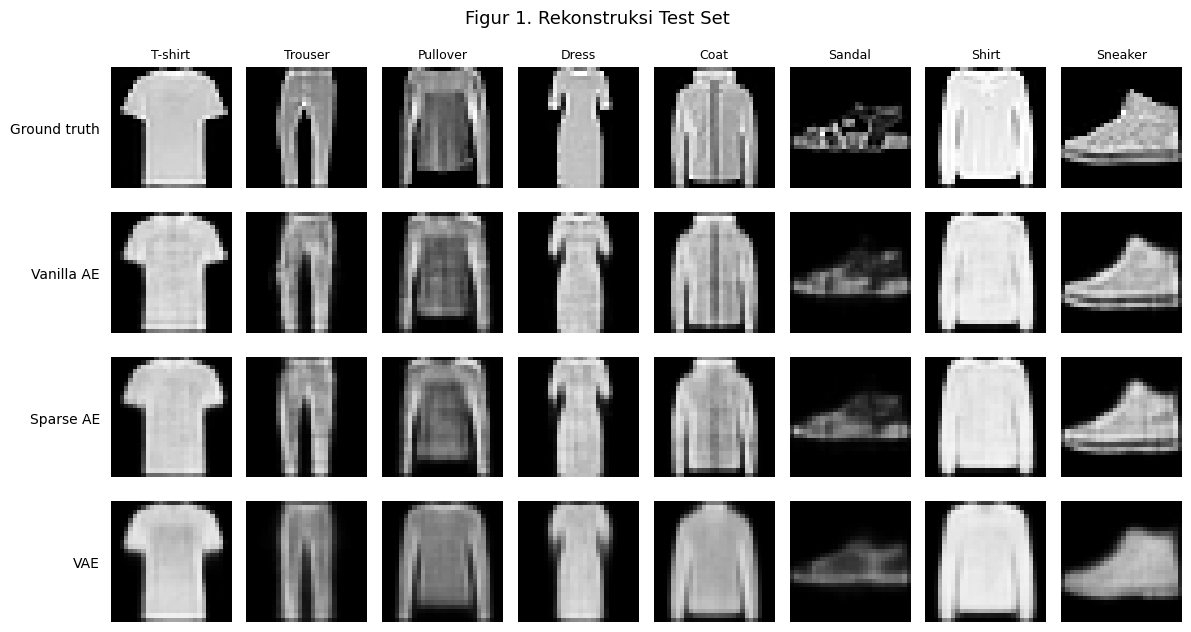

In [27]:
x8 = x_test[idx].to(device)
with torch.no_grad():
    rows = [("Ground truth", x8.cpu())] + [(n, m.decode(m.encode(x8)).cpu())
                                            for n, m in [("Vanilla AE", ae), ("Sparse AE", sae), ("VAE", vae)]]
fig, axes = plt.subplots(4, 8, figsize=(12, 6.5))
for r, (title, imgs) in enumerate(rows):
    for c in range(8):
        axes[r, c].imshow(imgs[c, 0], cmap="gray", vmin=0, vmax=1); axes[r, c].axis("off")
        if r == 0: axes[r, c].set_title(CLASSES[c], fontsize=9)
    axes[r, 0].text(-3, 14, title, ha="right", va="center", fontsize=10)
fig.suptitle("Figur 1. Rekonstruksi Test Set", fontsize=13)
plt.tight_layout(); plt.savefig("outputs/fig1_reconstruction.png", dpi=300); plt.show()

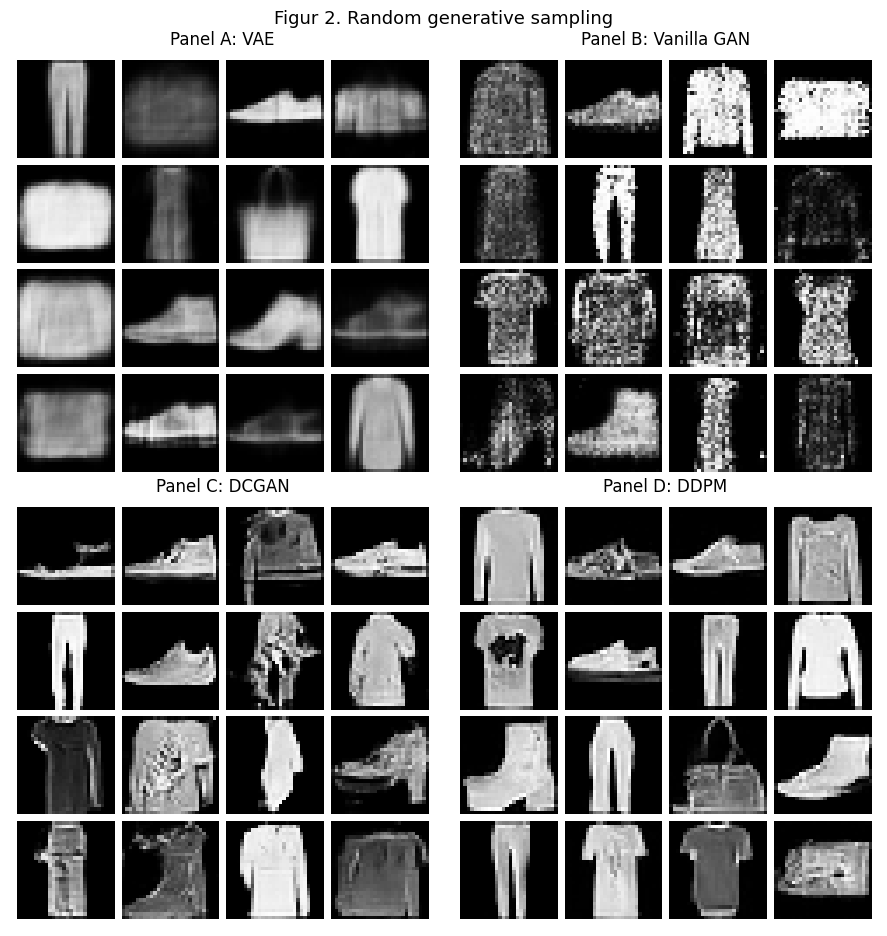

In [28]:
set_seed()
fig, axes = plt.subplots(2, 2, figsize=(9, 9.5))
for ax, name, panel in zip(axes.flat, ["VAE", "Vanilla GAN", "DCGAN", "DDPM"], "ABCD"):
    show_grid(generate(name, 16), nrow=4, title=f"Panel {panel}: {name}", ax=ax)
fig.suptitle("Figur 2. Random generative sampling", fontsize=13)
plt.tight_layout(); plt.savefig("outputs/fig2_sampling.png", dpi=300); plt.show()

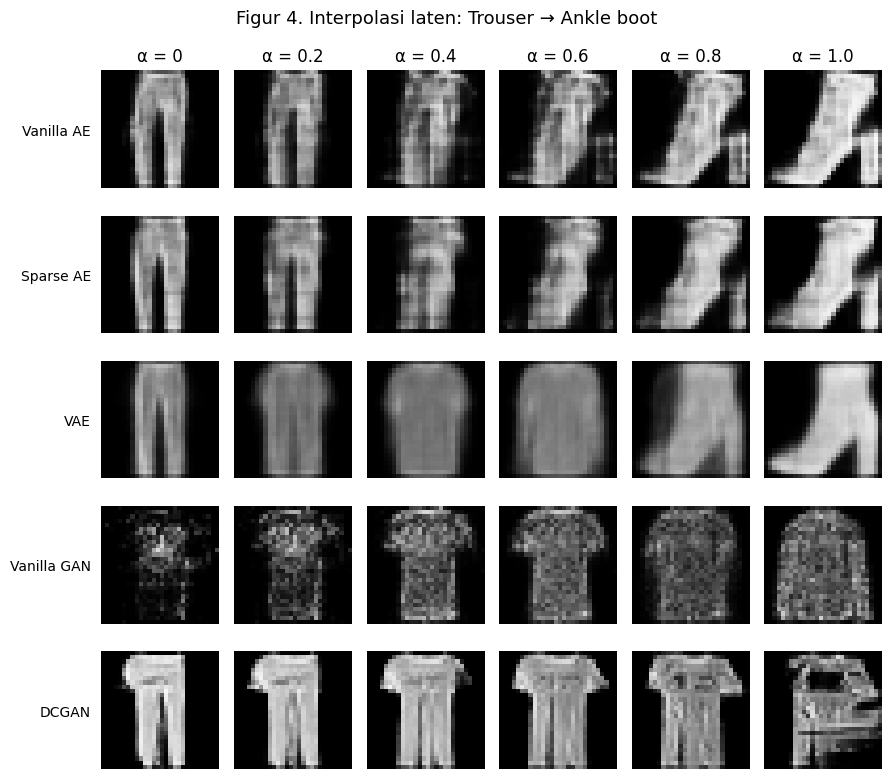

In [29]:
alpha_list = [0, 0.2, 0.4, 0.6, 0.8, 1.0]
xa = x_test[y_test == 1][:1].to(device)
xb = x_test[y_test == 9][:1].to(device)
set_seed()
za_gan, zb_gan = torch.randn(1, NZ, device=device), torch.randn(1, NZ, device=device)

fig, axes = plt.subplots(5, 6, figsize=(9, 8))
with torch.no_grad():
    for r, name in enumerate(["Vanilla AE", "Sparse AE", "VAE", "Vanilla GAN", "DCGAN"]):
        for c, a in enumerate(alpha_list):
            if name in ("Vanilla AE", "Sparse AE", "VAE"):
                m = {"Vanilla AE": ae, "Sparse AE": sae, "VAE": vae}[name]
                img = m.decode((1 - a) * m.encode(xa) + a * m.encode(xb))
            else:
                G = gan_G if name == "Vanilla GAN" else dcgan_G
                img = to_0_1(G((1 - a) * za_gan + a * zb_gan))
            axes[r, c].imshow(img[0, 0].cpu(), cmap="gray", vmin=0, vmax=1); axes[r, c].axis("off")
            if r == 0: axes[r, c].set_title(f"α = {a}")
        axes[r, 0].text(-3, 14, name, ha="right", va="center", fontsize=10)
fig.suptitle("Figur 4. Interpolasi laten: Trouser → Ankle boot", fontsize=13)
plt.tight_layout(); plt.savefig("outputs/fig4_interpolation.png", dpi=300); plt.show()

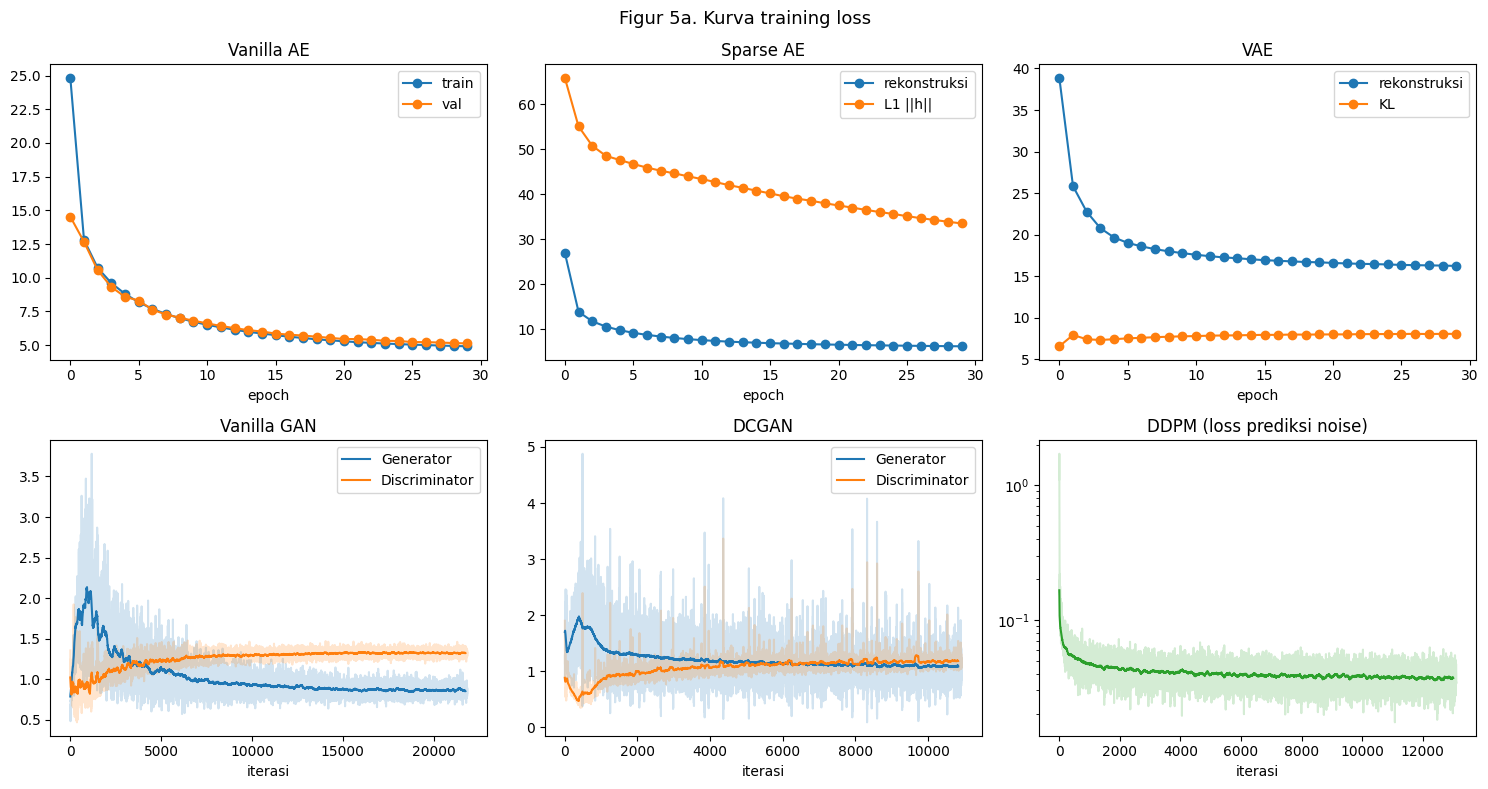

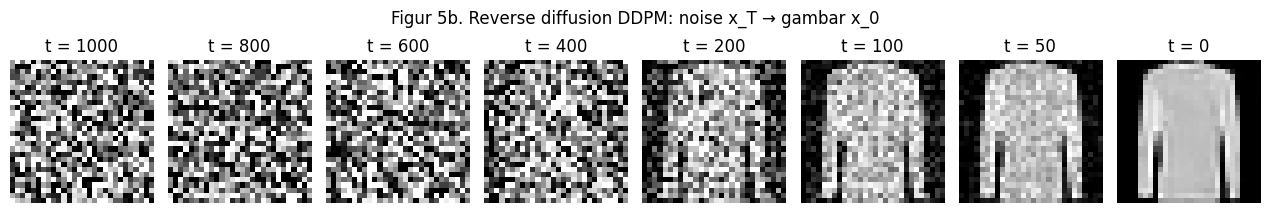

In [30]:
def smooth(v, k=100):
    k = max(1, min(k, len(v) // 5))
    return np.convolve(v, np.ones(k) / k, mode="valid")

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes[0, 0].plot(hist_ae["train"], "o-", label="train"); axes[0, 0].plot(hist_ae["val"], "o-", label="val")
axes[0, 0].set_title("Vanilla AE")
axes[0, 1].plot(hist_sae["recon"], "o-", label="rekonstruksi"); axes[0, 1].plot(hist_sae["reg"], "o-", label="L1 ||h||")
axes[0, 1].set_title("Sparse AE")
axes[0, 2].plot(hist_vae["recon"], "o-", label="rekonstruksi"); axes[0, 2].plot(hist_vae["reg"], "o-", label="KL")
axes[0, 2].set_title("VAE")
for ax in axes[0]:
    ax.set_xlabel("epoch"); ax.legend()

for ax, name, h in [(axes[1, 0], "Vanilla GAN", hist_gan), (axes[1, 1], "DCGAN", hist_dcgan)]:
    ax.plot(h["G"], color="C0", alpha=0.2); ax.plot(h["D"], color="C1", alpha=0.2)
    ax.plot(smooth(h["G"]), color="C0", label="Generator"); ax.plot(smooth(h["D"]), color="C1", label="Discriminator")
    ax.set_title(name); ax.set_xlabel("iterasi"); ax.legend()
axes[1, 2].plot(hist_ddpm["loss"], color="C2", alpha=0.2); axes[1, 2].plot(smooth(hist_ddpm["loss"]), color="C2")
axes[1, 2].set_yscale("log"); axes[1, 2].set_title("DDPM (loss prediksi noise)"); axes[1, 2].set_xlabel("iterasi")
fig.suptitle("Figur 5a. Kurva training loss", fontsize=13)
plt.tight_layout(); plt.savefig("outputs/fig5_loss.png", dpi=300); plt.show()

set_seed()
steps = sorted({T, int(T * 0.8), int(T * 0.6), int(T * 0.4), int(T * 0.2), int(T * 0.1), int(T * 0.05), 0}, reverse=True)
_, saved = ddpm_sample(ddpm, 1, keep=set(steps))
fig, axes = plt.subplots(1, len(steps), figsize=(1.6 * len(steps), 2.2))
for ax, t in zip(axes, steps):
    ax.imshow(to_0_1(saved[t])[0, 0].cpu(), cmap="gray", vmin=0, vmax=1); ax.axis("off"); ax.set_title(f"t = {t}")
fig.suptitle("Figur 5b. Reverse diffusion DDPM: noise x_T → gambar x_0", fontsize=12)
plt.tight_layout(); plt.savefig("outputs/fig5_ddpm_trajectory.png", dpi=300); plt.show()

In [1]:
!zip -r outputs.zip outputs


	zip warning: name not matched: outputs

zip error: Nothing to do! (try: zip -r outputs.zip . -i outputs)
